# J48 trên `ionosphere.arff` — bốc 70% train / 30% test nhiều lần

**Mục tiêu:** chia data 70/30 thật nhiều kiểu khác nhau, mỗi lần chạy J48 rồi lấy **Correctly Classified Instances** (số câu đoán đúng trên tập test). Gom hết lại vẽ biểu đồ để xem nó lên xuống cỡ nào.

**Ghi chú về J48 trong Python:** J48 là cây C4.5 của Weka (viết bằng Java). Python không có J48 "chính chủ", nên ở đây dùng `DecisionTreeClassifier` của scikit-learn chỉnh cho giống J48 nhất:
- `criterion="entropy"` → chọn câu hỏi chia nhánh theo information gain giống C4.5
- `min_samples_leaf=2` → giống `minNumObj = 2` mặc định của J48

Bộ ionosphere toàn cột số, nên cách cắt nhánh (≤ / >) giống J48. Khác chủ yếu ở bước tỉa cây (pruning), nên con số có thể lệch Weka vài câu, nhưng **hình dạng dao động** thì gần như y chang.

In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import arff
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix

## 1. Đọc file ARFF
Để file `ionosphere.arff` cùng thư mục với notebook (file này có sẵn trong thư mục `data` lúc cài Weka).

In [2]:
data, meta = arff.loadarff("ionosphere.arff")
df = pd.DataFrame(data)
df["class"] = df["class"].str.decode("utf-8")   # đổi b'g' -> 'g'

X = df.drop(columns="class").values
y = df["class"].values

print("Số dòng:", len(df), "| Số cột thuộc tính:", X.shape[1])
print(df["class"].value_counts())

Số dòng: 351 | Số cột thuộc tính: 34
class
g    225
b    126
Name: count, dtype: int64


## 2. Có thử *hết tất cả* cách bốc được không?
Weka chia 70% của 351 dòng → train **246** dòng, test **105** dòng.

Số cách chọn 246 dòng trong 351 dòng là tổ hợp C(351, 246). Chạy cell dưới để thấy nó lớn cỡ nào.

In [3]:
n = len(df)
n_train = round(n * 0.70)   # 246 dòng train, Weka làm tròn giống vậy
n_test = n - n_train
so_cach = math.comb(n, n_train)

print(f"Train = {n_train} dòng, Test = {n_test} dòng")
print(f"Số cách bốc = C({n}, {n_train}) ≈ 10^{len(str(so_cach)) - 1}  (có {len(str(so_cach))} chữ số)")

# Giả sử máy chạy 1 triệu lần/giây
nam = so_cach / 1_000_000 / (3600 * 24 * 365)
print(f"Chạy 1 triệu lần/giây thì mất khoảng 10^{len(str(int(nam))) - 1} năm")

Train = 246 dòng, Test = 105 dòng
Số cách bốc = C(351, 246) ≈ 10^91  (có 92 chữ số)
Chạy 1 triệu lần/giây thì mất khoảng 10^78 năm


➡️ Con số đó còn lớn hơn số nguyên tử trong vũ trụ, nên **không thể thử hết**.

Cách làm thực tế: **bốc ngẫu nhiên thật nhiều lần** (ví dụ 2000 lần). Giống như muốn biết nồi canh mặn hay nhạt thì múc nếm vài chục muỗng ở nhiều chỗ, chứ không cần uống hết nồi. 2000 lần là đủ để thấy rõ hình dạng dao động; muốn mịn hơn thì tăng `N_LAN`.

In [4]:
N_LAN = 2000          # số lần bốc ngẫu nhiên (tăng lên 10000 nếu muốn)

def tao_j48():
    """Cây quyết định chỉnh cho giống J48 mặc định."""
    return DecisionTreeClassifier(criterion="entropy", min_samples_leaf=2, random_state=0)

## 3. Thử 1 lần trước cho quen (in ra giống Weka)

In [5]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, train_size=n_train, random_state=1)
model = tao_j48().fit(X_tr, y_tr)
y_du_doan = model.predict(X_te)

dung = (y_du_doan == y_te).sum()
sai = len(y_te) - dung
print(f"Correctly Classified Instances   {dung:4d}   {dung / len(y_te) * 100:6.2f} %")
print(f"Incorrectly Classified Instances {sai:4d}   {sai / len(y_te) * 100:6.2f} %")
print("Số lá (Number of Leaves):", model.get_n_leaves())
print("\nConfusion matrix (hàng = thật, cột = đoán), thứ tự lớp:", model.classes_)
print(confusion_matrix(y_te, y_du_doan, labels=model.classes_))

Correctly Classified Instances     91    86.67 %
Incorrectly Classified Instances   14    13.33 %
Số lá (Number of Leaves): 16

Confusion matrix (hàng = thật, cột = đoán), thứ tự lớp: ['b' 'g']
[[29  7]
 [ 7 62]]


## 4. Bốc 2000 lần, mỗi lần một kiểu chia khác nhau
`random_state = i` → mỗi số `i` là một cách xáo bài khác nhau, nên mỗi lần là một tập train/test khác.

In [6]:
ket_qua = []
for i in range(N_LAN):
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, train_size=n_train, random_state=i)
    model = tao_j48().fit(X_tr, y_tr)
    dung = int((model.predict(X_te) == y_te).sum())
    ket_qua.append({"lan": i, "correct": dung, "phan_tram": dung / len(y_te) * 100,
                    "so_la": model.get_n_leaves()})

kq = pd.DataFrame(ket_qua)
kq.head()

,lan,correct,phan_tram,so_la
0,0,94,89.523810,15
1,1,91,86.666667,16
2,2,92,87.619048,15
3,3,94,89.523810,17
4,4,94,89.523810,16


## 5. Tóm tắt con số

In [7]:
c = kq["correct"]
p = kq["phan_tram"]
print(f"Số lần chạy        : {len(kq)}")
print(f"Trung bình         : {c.mean():.1f} / {n_test} câu đúng  ({p.mean():.2f} %)")
print(f"Độ lệch chuẩn (std): {c.std():.2f} câu  ({p.std():.2f} %)")
print(f"Tệ nhất            : {c.min()} câu ({p.min():.2f} %)")
print(f"Tốt nhất           : {c.max()} câu ({p.max():.2f} %)")
lo, hi = np.percentile(p, [2.5, 97.5])
print(f"95% số lần rơi vào : {lo:.2f} % → {hi:.2f} %")

Số lần chạy        : 2000
Trung bình         : 92.2 / 105 câu đúng  (87.80 %)
Độ lệch chuẩn (std): 3.23 câu  (3.07 %)
Tệ nhất            : 79 câu (75.24 %)
Tốt nhất           : 101 câu (96.19 %)
95% số lần rơi vào : 80.95 % → 93.33 %


## 6. Vẽ distribution

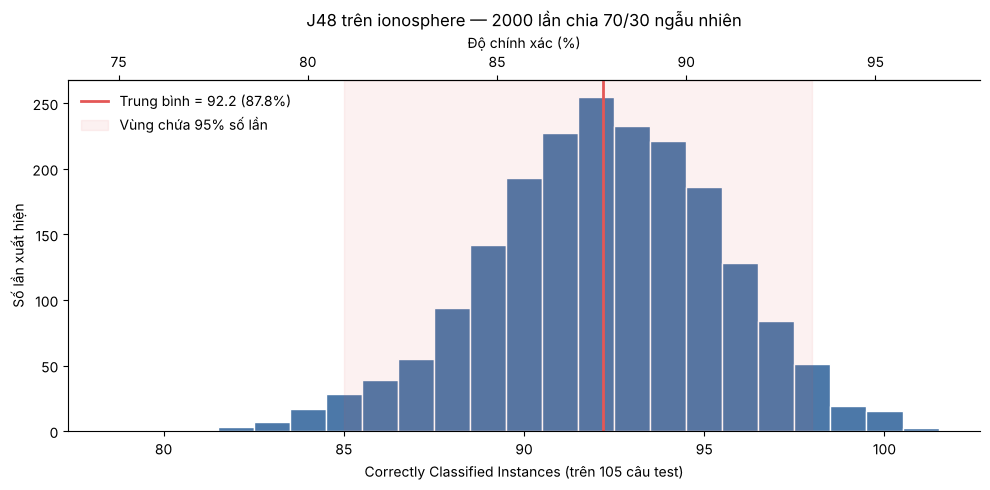

In [8]:
fig, ax = plt.subplots(figsize=(10, 5))

# mỗi cột = 1 giá trị số câu đúng (vì số câu đúng là số nguyên)
bins = np.arange(c.min() - 0.5, c.max() + 1.5, 1)
ax.hist(c, bins=bins, color="#4C78A8", edgecolor="white")

ax.axvline(c.mean(), color="#E45756", linewidth=2, label=f"Trung bình = {c.mean():.1f} ({p.mean():.1f}%)")
ax.axvspan(np.percentile(c, 2.5), np.percentile(c, 97.5), color="#E45756", alpha=0.08,
           label="Vùng chứa 95% số lần")

ax.set_title(f"J48 trên ionosphere — {N_LAN} lần chia 70/30 ngẫu nhiên")
ax.set_xlabel(f"Correctly Classified Instances (trên {n_test} câu test)")
ax.set_ylabel("Số lần xuất hiện")

# trục phụ phía trên hiển thị %
sec = ax.secondary_xaxis("top", functions=(lambda x: x / n_test * 100, lambda x: x * n_test / 100))
sec.set_xlabel("Độ chính xác (%)")

ax.spines[["right"]].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig("j48_ionosphere_distribution.png", dpi=150)
plt.show()

## 7. (Thêm) So với cách Weka chia mặc định
Weka Explorer → *Percentage split 70%* chỉ chia **đúng 1 lần** (seed = 1), tức là chỉ cho bạn **1 điểm** trong biểu đồ trên. Cell dưới lấy lần chia số 1 ở đây làm ví dụ xem 1 lần đó đứng ở đâu so với 2000 lần.

*(Lưu ý: seed 1 của Python xáo khác seed 1 của Weka, nên không ra cùng tập test — chỉ minh hoạ ý tưởng.)*

In [9]:
mot_lan = kq.loc[kq["lan"] == 1, "correct"].iloc[0]
hang = (c < mot_lan).mean() * 100
print(f"Lần chia seed=1 được {mot_lan} câu đúng → cao hơn {hang:.0f}% số lần còn lại")
print("=> Chỉ nhìn 1 lần chia thì có thể gặp lúc may hoặc lúc xui, nên đừng tin 1 con số duy nhất.")

Lần chia seed=1 được 91 câu đúng → cao hơn 29% số lần còn lại
=> Chỉ nhìn 1 lần chia thì có thể gặp lúc may hoặc lúc xui, nên đừng tin 1 con số duy nhất.
